Humanフォルダ: c:\Users\Admin\2026-\one-sentence\Human
Qwenフォルダ: c:\Users\Admin\2026-\one-sentence\Qwen
出力フォルダ: c:\Users\Admin\2026-\one-sentence\Qwen
===== データ数 =====
Train:
label
AI       480
Human    350
Name: count, dtype: int64

Test:
label
AI       164
Human    103
Name: count, dtype: int64

Train NaN: 0
Test NaN: 0


c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.ven


SHAP shape: (267, 53)
Test shape: (267, 53)


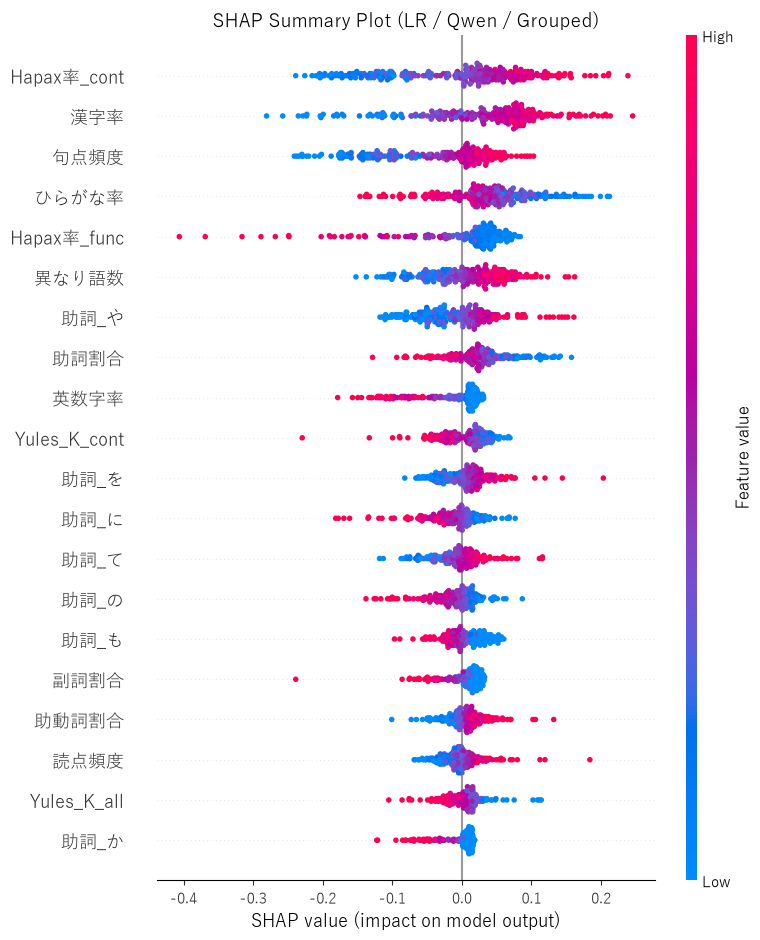

Beeswarm Plot保存: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_summary_Qwen_Grouped.png

SHAP分析完了
グループ別結果: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_group_results_Qwen.csv
特徴量別結果: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_feature_details_Qwen.csv
グループ数: 5
特徴量数: 53
対象文数: 267


In [1]:

import os
import numpy as np
import pandas as pd
import shap
# 日本語フォント設定
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Yu Gothic"
plt.rcParams["axes.unicode_minus"] = False

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler



# ==========================================
# 1. 特徴量グループ
# ==========================================

feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合",
        "連体詞割合", "接続詞割合",
        "助詞_と", "助詞_は", "助詞_の", "助詞_で",
        "助詞_て", "助詞_に", "助詞_や", "助詞_を",
        "助詞_ば", "助詞_が", "助詞_も", "助詞_つつ",
        "助詞_から", "助詞_など", "助詞_へ", "助詞_まで",
        "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],

    "内容語": [
        "内容語率", "名詞割合", "動詞割合",
        "形容詞割合", "形状詞割合", "副詞割合",
        "感動詞割合"
    ],

    "語彙多様性・反復": [
        "異なり語数", "TTR",
        "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],

    "文長・文構造": [
        "総単語数", "文長標準偏差",
        "最大文長", "平均文長"
    ],

    "表記・句読点": [
        "ひらがな率", "カタカナ率",
        "漢字率", "英数字率",
        "読点頻度", "句点頻度",
        "感嘆符数", "疑問符数"
    ]
}

feature_mode = "Grouped"


# ==========================================
# 2. データ読み込み
# ==========================================

# one-sentenceフォルダを基準にする
current_dir = os.getcwd()

# 実行場所に応じてone-sentenceの場所を取得
if os.path.basename(os.path.normpath(current_dir)) == "one-sentence":
    one_sentence_dir = current_dir

elif os.path.basename(os.path.normpath(current_dir)) in [
    "Human", "Qwen", "ChatGPT", "AI確信度"
]:
    one_sentence_dir = os.path.dirname(current_dir)

else:
    one_sentence_dir = os.path.join(
        current_dir, "one-sentence"
    )

human_dir = os.path.join(one_sentence_dir, "Human")
Qwen_dir = os.path.join(one_sentence_dir, "Qwen")

output_dir = Qwen_dir
os.makedirs(output_dir, exist_ok=True)

print("Humanフォルダ:", human_dir)
print("Qwenフォルダ:", Qwen_dir)
print("出力フォルダ:", output_dir)

# 学習データ
df_train_human = pd.read_csv(
    os.path.join(
        human_dir,
        "train_Human_one_sentence_stylometry_features.csv"
    )
)

df_train_Qwen = pd.read_csv(
    os.path.join(
        Qwen_dir,
        "train_Qwen_one_sentence_stylometry_features.csv"
    )
)

# テストデータ
df_test_human = pd.read_csv(
    os.path.join(
        human_dir,
        "test_Human_one_sentence_stylometry_features.csv"
    )
)

df_test_Qwen = pd.read_csv(
    os.path.join(
        Qwen_dir,
        "test_Qwen_one_sentence_stylometry_features.csv"
    )
)

# ==========================================
# 3. ラベル付け・データ結合
# ==========================================

df_train_human["label"] = "Human"
df_train_Qwen["label"] = "AI"

df_test_human["label"] = "Human"
df_test_Qwen["label"] = "AI"

df_train = pd.concat(
    [df_train_human, df_train_Qwen],
    ignore_index=True
)

df_test = pd.concat(
    [df_test_human, df_test_Qwen],
    ignore_index=True
)

print("===== データ数 =====")
print("Train:")
print(df_train["label"].value_counts())

print("\nTest:")
print(df_test["label"].value_counts())

# ==========================================
# 4. 特徴量の準備
# ==========================================

base_features = list(dict.fromkeys(
    feature
    for features in feature_groups.values()
    for feature in features
))

# 不足している特徴量を0で追加
for col in base_features:

    if col not in df_train.columns:
        df_train[col] = 0.0

    if col not in df_test.columns:
        df_test[col] = 0.0

# 数値型に変換
df_train[base_features] = df_train[base_features].apply(
    pd.to_numeric, errors="coerce"
)

df_test[base_features] = df_test[base_features].apply(
    pd.to_numeric, errors="coerce"
)

# NaN・正負の無限大を0に置換
df_train[base_features] = (
    df_train[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df_test[base_features] = (
    df_test[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print("\nTrain NaN:",
      df_train[base_features].isna().sum().sum())

print("Test NaN:",
      df_test[base_features].isna().sum().sum())

# ==========================================
# 5. LRの学習
# ==========================================

X_train = df_train[base_features]
X_test = df_test[base_features]

y_train = df_train["label"]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(
    max_iter=5000,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train_scaled, y_train)

ai_index = list(model.classes_).index("AI")

# ==========================================
# 6. SHAP計算
# ==========================================

def predict_ai_probability(X):

    X = np.asarray(X, dtype=float)

    # 学習時と同じ標準化を適用
    X_scaled = scaler.transform(X)

    return model.predict_proba(X_scaled)[:, ai_index]


# 学習データから背景データを抽出
background = (
    X_train
    .sample(
        n=min(100, len(X_train)),
        random_state=42
    )
    .to_numpy()
)

explainer = shap.Explainer(
    predict_ai_probability,
    shap.maskers.Independent(
        background,
        max_samples=len(background)
    ),
    algorithm="permutation"
)

# テストデータのAI確率に対するSHAP値
shap_result = explainer(
    X_test.to_numpy(),
    max_evals=10 * (2 * len(base_features) + 1)
)

shap_values = np.asarray(shap_result.values)

# 形状確認
print("\nSHAP shape:", shap_values.shape)
print("Test shape:", X_test.shape)

if shap_values.shape != X_test.shape:
    raise ValueError(
        "SHAP値とテストデータの形状が一致していません。"
    )


# ==========================================
# 7. SHAP Beeswarm Plot
# ==========================================

plt.figure(figsize=(12, 10))

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=base_features,
    max_display=20,
    plot_type="dot",
    show=False
)

plt.title(
    "SHAP Summary Plot (LR / Qwen / Grouped)",
    fontsize=14
)

plt.tight_layout()

output_path = os.path.join(
    output_dir,
    "SHAP_summary_Qwen_Grouped.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Beeswarm Plot保存:", output_path)


# ==========================================
# 8. グループ別・特徴量別に集約
# ==========================================

group_rows = []
feature_rows = []

feature_index = {
    name: i for i, name in enumerate(base_features)
}

for row_idx, row in df_test.iterrows():

    values = shap_values[row_idx]

    doc_id = (
        row["doc_id"]
        if "doc_id" in df_test.columns
        else (
            row["filename"]
            if "filename" in df_test.columns
            else row_idx
        )
    )

    label = row["label"]

    sent_order = (
        row["sent_order"]
        if "sent_order" in df_test.columns
        else row_idx + 1
    )

    # 特徴量別SHAP値
    for feature in base_features:

        j = feature_index[feature]

        belonging_group = next(
            group
            for group, features in feature_groups.items()
            if feature in features
        )

        feature_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量": feature,
            "所属グループ": belonging_group,
            "SHAP値": values[j],
            "SHAP絶対値": abs(values[j])
        })

    # グループ別SHAP値
    for group, features in feature_groups.items():

        indices = [
            feature_index[f]
            for f in features
        ]

        group_values = values[indices]

        group_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量グループ": group,
            "グループSHAP合計": np.sum(group_values),
            "グループSHAP絶対値合計": np.sum(
                np.abs(group_values)
            ),
            "グループ内平均絶対SHAP値": np.mean(
                np.abs(group_values)
            ),
            "グループ内特徴量数": len(features)
        })

# ==========================================
# 9. CSV保存
# ==========================================

df_group_shap = pd.DataFrame(group_rows)
df_feature_shap = pd.DataFrame(feature_rows)

group_path = os.path.join(
    output_dir,
    "SHAP_group_results_Qwen.csv"
)

feature_path = os.path.join(
    output_dir,
    "SHAP_feature_details_Qwen.csv"
)

df_group_shap.to_csv(
    group_path,
    index=False,
    encoding="utf-8-sig"
)

df_feature_shap.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSHAP分析完了")
print("グループ別結果:", group_path)
print("特徴量別結果:", feature_path)
print("グループ数:", len(feature_groups))
print("特徴量数:", len(base_features))
print("対象文数:", len(df_test))


Humanフォルダ: c:\Users\Admin\2026-\one-sentence\Human
AIフォルダ: c:\Users\Admin\2026-\one-sentence\Qwen
出力フォルダ: c:\Users\Admin\2026-\one-sentence\Qwen

===== データ数 =====
Train:
label
AI       480
Human    350
Name: count, dtype: int64

Test:
label
AI       164
Human    103
Name: count, dtype: int64

===== データ数 =====
Train:
label
AI       480
Human    350
Name: count, dtype: int64

Test:
label
AI       164
Human    103
Name: count, dtype: int64

Train NaN: 0
Test NaN: 0

RF学習完了
学習データ数: 830
特徴量数: 53


c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
c:\Users\Admin\2026-\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  


SHAP shape: (267, 53)
Test shape: (267, 53)


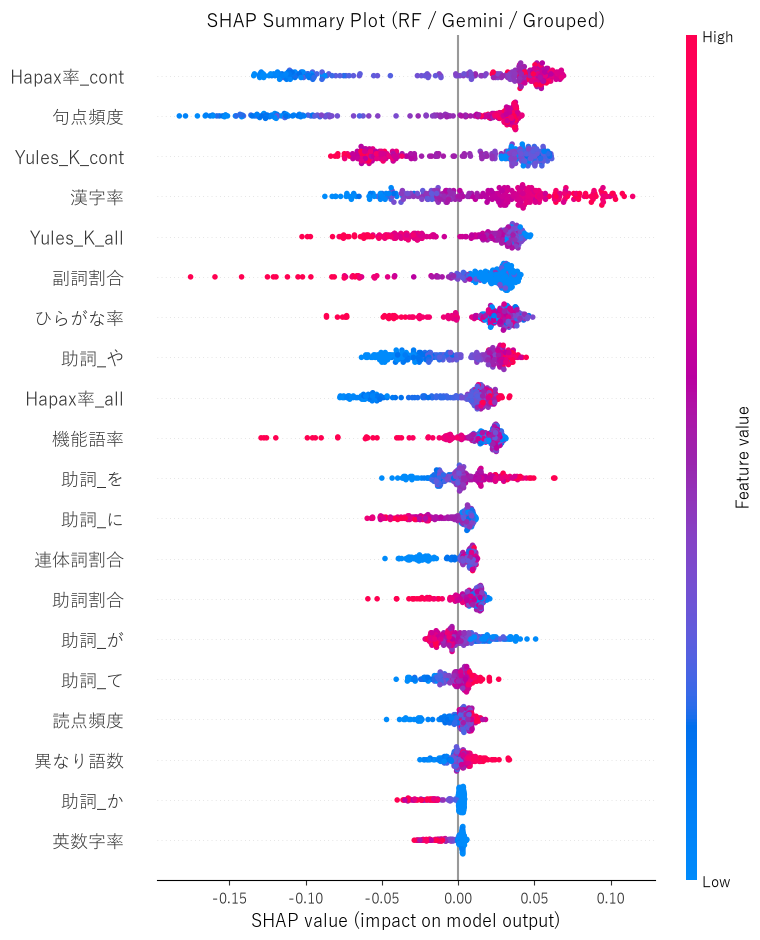

Beeswarm Plot保存: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_summary_Gemini_Grouped_RF.png

RF SHAP分析完了
グループ別結果: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_group_results_Gemini_RF.csv
特徴量別結果: c:\Users\Admin\2026-\one-sentence\Qwen\SHAP_feature_details_Gemini_RF.csv
グループ数: 5
特徴量数: 53
対象文数: 267


In [5]:

import os
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier

# ==========================================
# 0. 日本語フォント設定
# ==========================================

plt.rcParams["font.family"] = "Yu Gothic"
plt.rcParams["axes.unicode_minus"] = False

# ==========================================
# 1. 特徴量グループ
# ==========================================

feature_groups = {
    "機能語": [
        "機能語率", "助詞割合", "助動詞割合",
        "連体詞割合", "接続詞割合",
        "助詞_と", "助詞_は", "助詞_の", "助詞_で",
        "助詞_て", "助詞_に", "助詞_や", "助詞_を",
        "助詞_ば", "助詞_が", "助詞_も", "助詞_つつ",
        "助詞_から", "助詞_など", "助詞_へ", "助詞_まで",
        "助詞_か", "助詞_たり", "助詞_だけ",
        "助詞_ながら", "助詞_より"
    ],

    "内容語": [
        "内容語率", "名詞割合", "動詞割合",
        "形容詞割合", "形状詞割合", "副詞割合",
        "感動詞割合"
    ],

    "語彙多様性・反復": [
        "異なり語数", "TTR",
        "Hapax率_all", "Yules_K_all",
        "Hapax率_func", "Yules_K_func",
        "Hapax率_cont", "Yules_K_cont"
    ],

    "文長・文構造": [
        "総単語数", "文長標準偏差",
        "最大文長", "平均文長"
    ],

    "表記・句読点": [
        "ひらがな率", "カタカナ率",
        "漢字率", "英数字率",
        "読点頻度", "句点頻度",
        "感嘆符数", "疑問符数"
    ]
}

feature_mode = "Grouped"


# ==========================================
# 2. データ読み込み
# ==========================================

current_dir = os.getcwd()

# one-sentenceフォルダを自動取得
parts = os.path.normpath(current_dir).split(os.sep)

if "one-sentence" in parts:
    idx = parts.index("one-sentence")
    one_sentence_dir = os.sep.join(parts[:idx + 1])

else:
    raise FileNotFoundError(
        "現在の作業ディレクトリからone-sentenceフォルダを特定できません。\n"
        f"現在の場所: {current_dir}"
    )

human_dir = os.path.join(one_sentence_dir, "Human")

# 実行対象のAIフォルダを取得
ai_dir = os.path.basename(os.path.normpath(current_dir))

if ai_dir not in ["ChatGPT", "Gemini", "Qwen"]:
    ai_dir = "Qwen"  # 必要に応じて変更

ai_data_dir = os.path.join(one_sentence_dir, ai_dir)

# 出力先は対象AIフォルダ
output_dir = ai_data_dir

print("Humanフォルダ:", human_dir)
print("AIフォルダ:", ai_data_dir)
print("出力フォルダ:", output_dir)

# 学習データ
df_train_human = pd.read_csv(
    os.path.join(
        human_dir,
        "train_Human_one_sentence_stylometry_features.csv"
    )
)

df_train_ai = pd.read_csv(
    os.path.join(
        ai_data_dir,
        f"train_{ai_dir}_one_sentence_stylometry_features.csv"
    )
)

# テストデータ
df_test_human = pd.read_csv(
    os.path.join(
        human_dir,
        "test_Human_one_sentence_stylometry_features.csv"
    )
)

df_test_ai = pd.read_csv(
    os.path.join(
        ai_data_dir,
        f"test_{ai_dir}_one_sentence_stylometry_features.csv"
    )
)

# ラベル付け
df_train_human["label"] = "Human"
df_train_ai["label"] = "AI"

df_test_human["label"] = "Human"
df_test_ai["label"] = "AI"

# 結合
df_train = pd.concat(
    [df_train_human, df_train_ai],
    ignore_index=True
)

df_test = pd.concat(
    [df_test_human, df_test_ai],
    ignore_index=True
)

print("\n===== データ数 =====")
print("Train:")
print(df_train["label"].value_counts())

print("\nTest:")
print(df_test["label"].value_counts())


# ==========================================
# 3. ラベル付け・データ結合
# ==========================================

df_train_human["label"] = "Human"
df_train_ai["label"] = "AI"

df_test_human["label"] = "Human"
df_test_ai["label"] = "AI"

df_train = pd.concat(
    [df_train_human, df_train_ai],
    ignore_index=True
)

df_test = pd.concat(
    [df_test_human, df_test_ai],
    ignore_index=True
)

print("\n===== データ数 =====")
print("Train:")
print(df_train["label"].value_counts())

print("\nTest:")
print(df_test["label"].value_counts())

# ==========================================
# 4. 特徴量の準備
# ==========================================

base_features = list(dict.fromkeys(
    feature
    for features in feature_groups.values()
    for feature in features
))

# 不足している特徴量を0で追加
for col in base_features:

    if col not in df_train.columns:
        df_train[col] = 0.0

    if col not in df_test.columns:
        df_test[col] = 0.0

# 数値型に変換
df_train[base_features] = df_train[base_features].apply(
    pd.to_numeric, errors="coerce"
)

df_test[base_features] = df_test[base_features].apply(
    pd.to_numeric, errors="coerce"
)

# NaN・正負の無限大を0に置換
df_train[base_features] = (
    df_train[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

df_test[base_features] = (
    df_test[base_features]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print("\nTrain NaN:",
      df_train[base_features].isna().sum().sum())

print("Test NaN:",
      df_test[base_features].isna().sum().sum())

# ==========================================
# 5. RFの学習
# ==========================================

X_train = df_train[base_features]
X_test = df_test[base_features]

y_train = df_train["label"]

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

ai_index = list(model.classes_).index("AI")

print("\nRF学習完了")
print("学習データ数:", len(X_train))
print("特徴量数:", len(base_features))

# ==========================================
# 6. SHAP計算
# ==========================================

def predict_ai_probability(X):

    X = np.asarray(X, dtype=float)

    return model.predict_proba(X)[:, ai_index]


# 学習データから背景データを抽出
background = (
    X_train
    .sample(
        n=min(100, len(X_train)),
        random_state=42
    )
    .to_numpy()
)

explainer = shap.Explainer(
    predict_ai_probability,
    shap.maskers.Independent(
        background,
        max_samples=len(background)
    ),
    algorithm="permutation"
)

# テストデータのAI確率に対するSHAP値
shap_result = explainer(
    X_test.to_numpy(),
    max_evals=10 * (2 * len(base_features) + 1)
)

shap_values = np.asarray(shap_result.values)

# 形状確認
print("\nSHAP shape:", shap_values.shape)
print("Test shape:", X_test.shape)

if shap_values.shape != X_test.shape:
    raise ValueError(
        "SHAP値とテストデータの形状が一致していません。"
    )

# ==========================================
# 7. SHAP Beeswarm Plot
# ==========================================

plt.figure(figsize=(12, 10))

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=base_features,
    max_display=20,
    plot_type="dot",
    show=False
)

plt.title(
    "SHAP Summary Plot (RF / Gemini / Grouped)",
    fontsize=14
)

plt.tight_layout()

output_path = os.path.join(
    output_dir,
    "SHAP_summary_Gemini_Grouped_RF.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Beeswarm Plot保存:", output_path)

# ==========================================
# 8. グループ別・特徴量別に集約
# ==========================================

group_rows = []
feature_rows = []

feature_index = {
    name: i for i, name in enumerate(base_features)
}

for row_idx, (_, row) in enumerate(df_test.iterrows()):

    values = shap_values[row_idx]

    doc_id = (
        row["doc_id"]
        if "doc_id" in df_test.columns
        else (
            row["filename"]
            if "filename" in df_test.columns
            else row_idx
        )
    )

    label = row["label"]

    sent_order = (
        row["sent_order"]
        if "sent_order" in df_test.columns
        else row_idx + 1
    )

    # 特徴量別SHAP値
    for feature in base_features:

        j = feature_index[feature]

        belonging_group = next(
            group
            for group, features in feature_groups.items()
            if feature in features
        )

        feature_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量": feature,
            "所属グループ": belonging_group,
            "SHAP値": values[j],
            "SHAP絶対値": abs(values[j])
        })

    # グループ別SHAP値
    for group, features in feature_groups.items():

        indices = [
            feature_index[f]
            for f in features
        ]

        group_values = values[indices]

        group_rows.append({
            "doc_id": doc_id,
            "sent_order": sent_order,
            "label": label,
            "特徴量グループ": group,
            "グループSHAP合計": np.sum(group_values),
            "グループSHAP絶対値合計": np.sum(
                np.abs(group_values)
            ),
            "グループ内平均絶対SHAP値": np.mean(
                np.abs(group_values)
            ),
            "グループ内特徴量数": len(features)
        })

# ==========================================
# 9. CSV保存
# ==========================================

df_group_shap = pd.DataFrame(group_rows)
df_feature_shap = pd.DataFrame(feature_rows)

group_path = os.path.join(
    output_dir,
    "SHAP_group_results_Gemini_RF.csv"
)

feature_path = os.path.join(
    output_dir,
    "SHAP_feature_details_Gemini_RF.csv"
)

df_group_shap.to_csv(
    group_path,
    index=False,
    encoding="utf-8-sig"
)

df_feature_shap.to_csv(
    feature_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nRF SHAP分析完了")
print("グループ別結果:", group_path)
print("特徴量別結果:", feature_path)
print("グループ数:", len(feature_groups))
print("特徴量数:", len(base_features))
print("対象文数:", len(df_test))
